Loading Strata Index...
Running PCA dimensionality reduction...


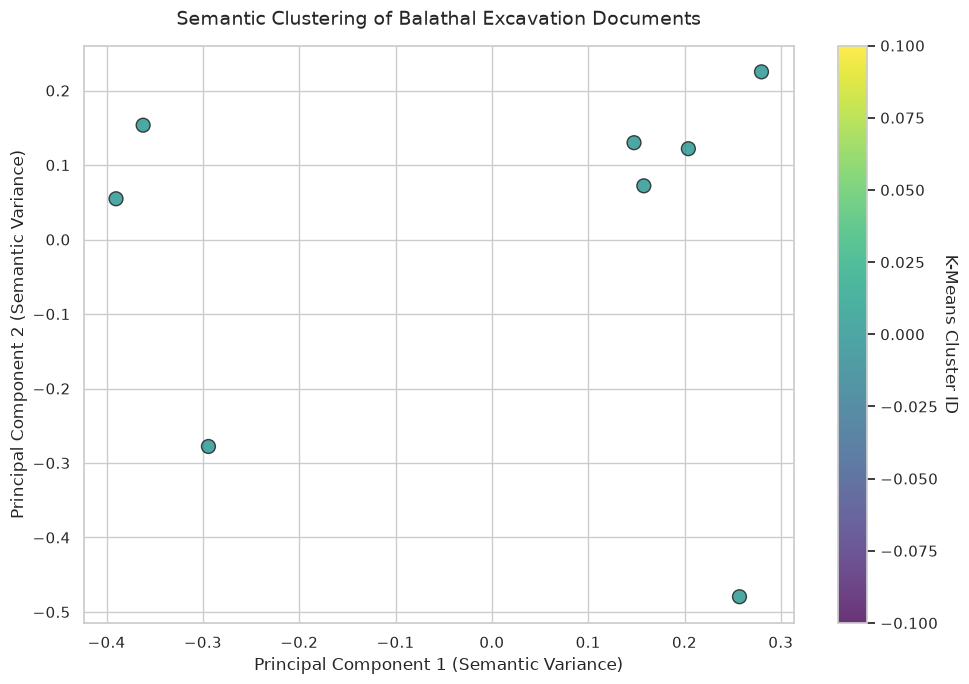

In [7]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

# 1. Load your existing Strata Index
print("Loading Strata Index...")
with open('index/strata_index.pkl', 'rb') as f:
    index = pickle.load(f)

# Automatically find the correct key for the dense vectors
if 'dense_embeddings' in index:
    dense_embeddings = index['dense_embeddings']
elif 'embeddings' in index:
    dense_embeddings = index['embeddings']
else:
    raise ValueError(f"Could not find embeddings. Available keys are: {list(index.keys())}")

cluster_labels = index.get('clusters', np.zeros(len(dense_embeddings)))

# 2. Reduce the high-dimensional embeddings to 2D for visualization
print("Running PCA dimensionality reduction...")
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(dense_embeddings)

# 3. Plot the semantic clusters
plt.figure(figsize=(10, 7))
sns.set_theme(style="whitegrid")

# Create a scatter plot colored by their K-Means cluster
scatter = plt.scatter(
    reduced_embeddings[:, 0], 
    reduced_embeddings[:, 1], 
    c=cluster_labels, 
    cmap='viridis', 
    s=100, 
    alpha=0.8,
    edgecolor='k'
)

plt.title("Semantic Clustering of Balathal Excavation Documents", fontsize=14, pad=15)
plt.xlabel("Principal Component 1 (Semantic Variance)", fontsize=12)
plt.ylabel("Principal Component 2 (Semantic Variance)", fontsize=12)

# Add a colorbar to show the different thematic clusters
cbar = plt.colorbar(scatter)
cbar.set_label('K-Means Cluster ID', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

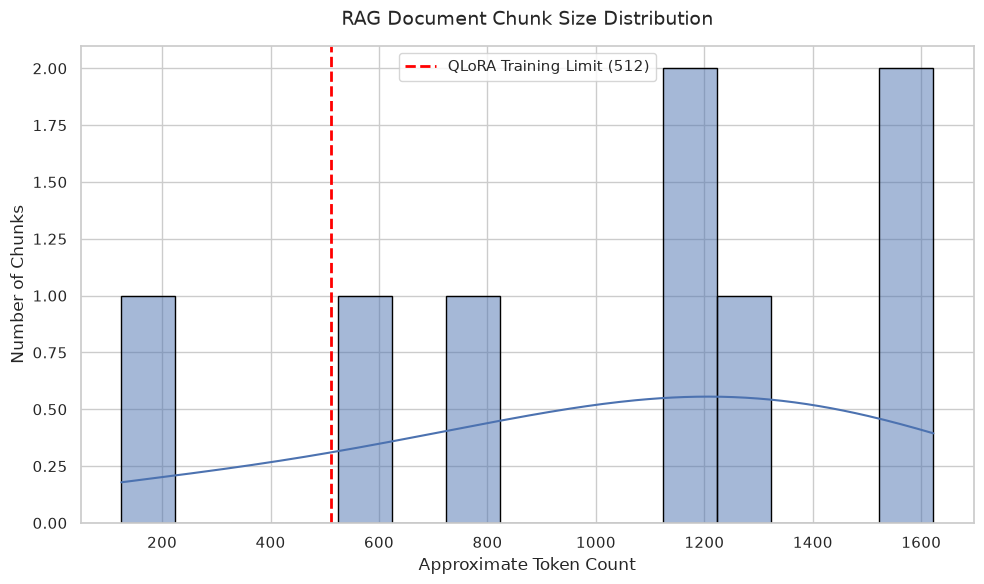

In [8]:
# Calculate the approximate token length of each document chunk (words * 1.3)
doc_lengths = [len(doc.split()) * 1.3 for doc in index['documents']]

plt.figure(figsize=(10, 6))
sns.histplot(doc_lengths, bins=15, kde=True, color='#4C72B0', edgecolor='black')

# Add a red dashed line representing your strict 512-token training limit
plt.axvline(x=512, color='red', linestyle='--', linewidth=2, label='QLoRA Training Limit (512)')

plt.title("RAG Document Chunk Size Distribution", fontsize=14, pad=15)
plt.xlabel("Approximate Token Count", fontsize=12)
plt.ylabel("Number of Chunks", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()

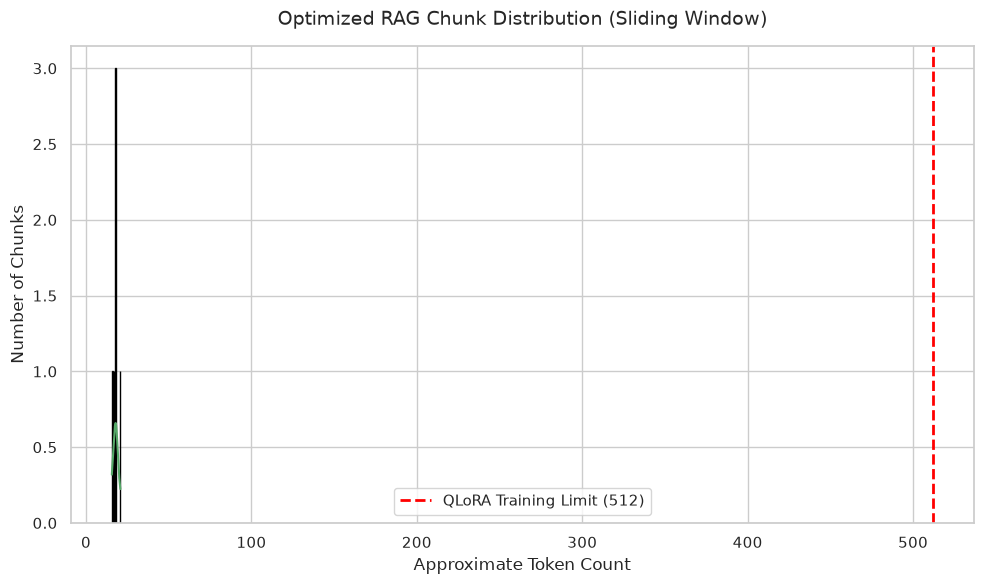

In [10]:
import pickle
import matplotlib.pyplot as plt
import seaborn as sns

# Load the newly rebuilt index
with open('index/strata_index.pkl', 'rb') as f:
    index = pickle.load(f)

# Calculate token lengths of the new sliding-window chunks
doc_lengths = [len(doc.split()) * 1.3 for doc in index['documents']]

plt.figure(figsize=(10, 6))
sns.histplot(doc_lengths, bins=10, kde=True, color='#55A868', edgecolor='black')

# The strict QLoRA training limit
plt.axvline(x=512, color='red', linestyle='--', linewidth=2, label='QLoRA Training Limit (512)')

plt.title("Optimized RAG Chunk Distribution (Sliding Window)", fontsize=14, pad=15)
plt.xlabel("Approximate Token Count", fontsize=12)
plt.ylabel("Number of Chunks", fontsize=12)
plt.legend()

plt.tight_layout()
plt.show()